<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_6/dataset_pbl/ANNOY/praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pertemuan 1**
## **Percobaan 1**

In [1]:
!pip install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 7.6 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520030 sha256=39cfdda61d22f7d94cbb70cbb8352ab5e33887c8062feb43c534cfc2856f3379
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy


Exact NN index: [121 120 119]
Exact NN jarak: [0. 0. 0.]
Waktu Exact: 4.6642 ms

Annoy NN index: [86, 101, 104]
Annoy NN jarak: [np.float32(0.0), np.float32(0.0), np.float32(0.0)]
Waktu Annoy: 0.114 ms


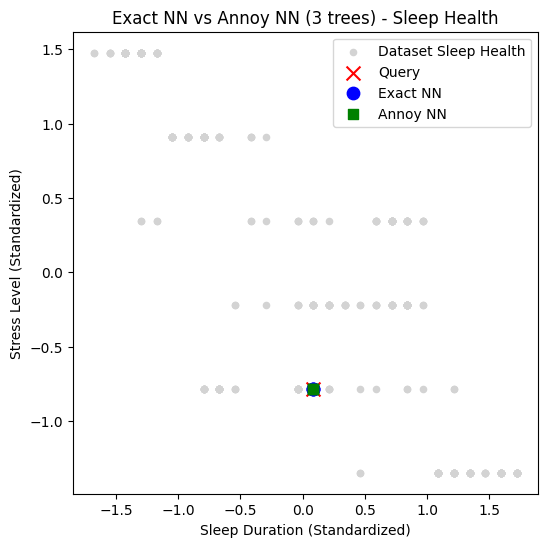

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.preprocessing import StandardScaler
from annoy import AnnoyIndex

# 1. Load & Standarisasi Dataset Sleep Health (2 Fitur: Sleep Duration & Stress Level)
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
fitur_2d = ['Sleep Duration', 'Stress Level']
X = StandardScaler().fit_transform(df[fitur_2d]).astype(np.float32)

# Query point (ambil data indeks ke-0 atau acak)
np.random.seed(42)
query = X[np.random.randint(0, len(X))]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact * 1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)
t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i] - query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann * 1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], c="lightgray", s=20, label="Dataset Sleep Health")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact, 0], X[idx_exact, 1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann, 0], X[idx_ann, 1], c="green", s=50, marker="s", label="Annoy NN")

plt.xlabel("Sleep Duration (Standardized)")
plt.ylabel("Stress Level (Standardized)")
plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees) - Sleep Health")
plt.show()

In [3]:
from scipy.spatial import distance

# Daftar kombinasi (metric, jumlah tree, jumlah data)
# 374 adalah jumlah data asli, 100000 adalah simulasi duplikasi skala besar
configs = [
    ('euclidean', 3, 374),
    ('euclidean', 8, 374),
    ('euclidean', 3, 100000),
    ('angular', 3, 374),
    ('angular', 8, 374),
    ('angular', 3, 100000)
]

hasil_eksperimen = []

for metric, n_trees, n_points in configs:
    # Siapkan Dataset Sleep Health
    if n_points == 374:
        X_exp = X.copy()
    else:
        # Perbanyak data Sleep Health hingga mencapai n_points untuk uji skala besar
        repeats = int(np.ceil(n_points / len(X)))
        X_exp = np.tile(X, (repeats, 1))[:n_points]

    np.random.seed(42)
    query = X_exp[np.random.randint(0, n_points)]

    # Exact NN (Brute Force)
    start = time.time()
    if metric == 'euclidean':
        distances = np.linalg.norm(X_exp - query, axis=1)
    else:
        distances = distance.cdist([query], X_exp, metric='cosine')[0]
    idx_exact = np.argsort(distances)[:3]
    time_exact = (time.time() - start) * 1000  # ms

    # Annoy NN (Approximate)
    f = 2
    t = AnnoyIndex(f, metric)
    for i, vec in enumerate(X_exp):
        t.add_item(i, vec)
    t.build(n_trees)

    start = time.time()
    idx_ann = t.get_nns_by_vector(query, 3)
    time_ann = (time.time() - start) * 1000  # ms

    str_idx_exact = f"[{idx_exact[0]} {idx_exact[1]} {idx_exact[2]}]"
    str_idx_ann = f"[{idx_ann[0]} {idx_ann[1]} {idx_ann[2]}]"

    hasil_eksperimen.append({
        'Distance Metrics': metric.capitalize(),
        'Tree': n_trees,
        'Jumlah data': n_points,
        'Hasil Index terdekat ENN vs ANN': f"{str_idx_exact}, {str_idx_ann}",
        'Waktu komputasi Vs (ms)': f"{time_exact:.4f}, {time_ann:.4f}"
    })

df_hasil = pd.DataFrame(hasil_eksperimen)
display(df_hasil)

,Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi Vs (ms)
0,Euclidean,3,374,"[121 120 119], [86 101 104]","0.1910, 0.0362"
1,Euclidean,8,374,"[121 120 119], [85 86 87]","0.1822, 0.0405"
2,Euclidean,3,100000,"[65199 62188 62186], [5338 7222 8719]","7.7207, 0.0484"
3,Angular,3,374,"[123 124 122], [94 96 100]","1.5275, 0.0305"
4,Angular,8,374,"[123 124 122], [85 86 87]","0.1991, 0.0455"
5,Angular,3,100000,"[56214 72302 72303], [2364 9435 18069]","10.0777, 0.0429"


In [4]:
from sklearn.metrics.pairwise import euclidean_distances

# Siapkan 7 fitur numerik dataset Sleep Health
fitur_7d = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']
X_7d = StandardScaler().fit_transform(df[fitur_7d]).astype(np.float32)

# Query profil responden baru (misalnya indeks ke-10)
query_profil = X_7d[10:11]

# Exact NN (brute force)
start = time.time()
distances = euclidean_distances(query_profil, X_7d)[0]
exact_idx = np.argsort(distances)[:5]  # ambil 5 profil terdekat
exact_time = time.time() - start

print("Exact NN result:", exact_idx)
print("Exact NN time:", round(exact_time * 1000, 4), "ms")

# Approx NN pakai Annoy
f = len(fitur_7d)
annoy_index = AnnoyIndex(f, 'euclidean')
n_trees = 3

for i in range(len(X_7d)):
    annoy_index.add_item(i, X_7d[i])
annoy_index.build(n_trees)

start = time.time()
annoy_idx = annoy_index.get_nns_by_vector(query_profil[0], 5)
annoy_time = time.time() - start

print("Annoy result:", annoy_idx)
print("Annoy time:", round(annoy_time * 1000, 4), "ms")

Exact NN result: [12 10 13 14 15]
Exact NN time: 6.0401 ms
Annoy result: [10, 12, 13, 14, 15]
Annoy time: 0.2098 ms


In [5]:
from sklearn.metrics.pairwise import cosine_distances

configs_p2 = [
    ('euclidean', 8, len(X_7d)),
    ('angular', 8, len(X_7d))
]

hasil_eksperimen_p2 = []

for metric, n_trees, n_data in configs_p2:
    # Exact NN
    start = time.time()
    if metric == 'euclidean':
        distances = euclidean_distances(query_profil, X_7d)[0]
    else:
        distances = cosine_distances(query_profil, X_7d)[0]
    exact_idx = np.argsort(distances)[:5]
    exact_time = (time.time() - start) * 1000  # ms

    # Annoy NN
    f = len(fitur_7d)
    annoy_index = AnnoyIndex(f, metric)
    for i in range(n_data):
        annoy_index.add_item(i, X_7d[i])
    annoy_index.build(n_trees)

    start = time.time()
    annoy_idx = annoy_index.get_nns_by_vector(query_profil[0], 5)
    annoy_time = (time.time() - start) * 1000  # ms

    str_idx_exact = "[" + " ".join(map(str, exact_idx)) + "]"
    str_idx_ann = "[" + " ".join(map(str, annoy_idx)) + "]"

    hasil_eksperimen_p2.append({
        'Distance Metrics': metric.capitalize(),
        'Tree': n_trees,
        'Jumlah data': n_data,
        'Hasil Index terdekat ENN vs ANN': f"{str_idx_exact}, {str_idx_ann}",
        'Waktu komputasi Vs (ms)': f"{exact_time:.4f}, {annoy_time:.4f}"
    })

df_hasil_p2 = pd.DataFrame(hasil_eksperimen_p2)
display(df_hasil_p2)

,Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi Vs (ms)
0,Euclidean,8,374,"[12 10 13 14 15], [10 12 13 14 15]","1.2577, 0.0498"
1,Angular,8,374,"[12 10 14 13 15], [10 12 13 14 15]","1.3056, 0.0598"


## **Pertanyaan**

Kenapa code dibagian build index tidak dihitung waktunya?
- Proses build indeks dilakukan secara offline (satu kali di awal) saat sistem menyiapkan data atau melakukan pembaruan basis data secara berkala, bukan dilakukan setiap kali pengguna melakukan pencarian.

Dalam sistem nyata (seperti sistem rekomendasi), hal yang paling menentukan pengalaman pengguna adalah waktu pencarian (query/retrieval time) secara real-time. Oleh karena itu, pengukuran waktu difokuskan pada saat fungsi get_nns_by_vector dijalankan untuk membandingkan seberapa cepat ANNOY menemukan tetangga terdekat dibandingkan perhitungan jarak satu per satu pada Exact Nearest Neighbors.